In [1]:
import pandas as pd

df = pd.read_csv("clean_nus_sms.csv")

df.head()

,Unnamed: 0,id,Message,length,country,Date
0,0,10120,Bugis oso near wat...,21,SG,2003/4
1,1,10121,"Go until jurong point, crazy.. Available only ...",111,SG,2003/4
2,2,10122,I dunno until when... Lets go learn pilates...,46,SG,2003/4
3,3,10123,Den only weekdays got special price... Haiz......,140,SG,2003/4
4,4,10124,Meet after lunch la...,22,SG,2003/4


In [2]:
df.shape

(48598, 6)

In [3]:
df.columns


Index(['Unnamed: 0', 'id', 'Message', 'length', 'country', 'Date'], dtype='str')

In [4]:
df["country"].value_counts().head(10)


country
Singapore        22013
SG                9806
India             6901
United States     3749
USA               1932
Sri Lanka         1017
Malaysia           766
Pakistan           751
unknown            602
Canada             198
Name: count, dtype: int64

In [5]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

df["clean_message"] = df["Message"].apply(clean_text)

df[["Message","clean_message"]].head()

,Message,clean_message
0,Bugis oso near wat...,bugis oso near wat
1,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
2,I dunno until when... Lets go learn pilates...,i dunno until when lets go learn pilates
3,Den only weekdays got special price... Haiz......,den only weekdays got special price haiz cant ...
4,Meet after lunch la...,meet after lunch la


In [6]:
from collections import Counter

all_words = " ".join(df["clean_message"])

word_counts = Counter(all_words.split())

word_counts.most_common(20)

[('i', 17410),
 ('to', 10641),
 ('u', 9870),
 ('you', 8780),
 ('the', 7995),
 ('haha', 6529),
 ('me', 4701),
 ('a', 4516),
 ('my', 4489),
 ('for', 4134),
 ('is', 4067),
 ('in', 4058),
 ('so', 3961),
 ('and', 3907),
 ('at', 3859),
 ('can', 3766),
 ('it', 3514),
 ('go', 3311),
 ('lol', 3000),
 ('not', 2957)]

SMS Text Analysis Using Natural Language Processing
Objective
The objective of this project is to analyze SMS message data using Natural Language Processing (NLP) techniques.

Techniques include:

Text preprocessing
Word frequency analysis
Sentiment analysis
Data visualization
The dataset contains SMS messages collected from users and includes message text, country, date, and message length.

In [7]:
df.shape

(48598, 7)

In [8]:
df["country"].value_counts().head(10)

country
Singapore        22013
SG                9806
India             6901
United States     3749
USA               1932
Sri Lanka         1017
Malaysia           766
Pakistan           751
unknown            602
Canada             198
Name: count, dtype: int64

In [9]:
word_counts.most_common(20)

[('i', 17410),
 ('to', 10641),
 ('u', 9870),
 ('you', 8780),
 ('the', 7995),
 ('haha', 6529),
 ('me', 4701),
 ('a', 4516),
 ('my', 4489),
 ('for', 4134),
 ('is', 4067),
 ('in', 4058),
 ('so', 3961),
 ('and', 3907),
 ('at', 3859),
 ('can', 3766),
 ('it', 3514),
 ('go', 3311),
 ('lol', 3000),
 ('not', 2957)]

In [10]:
df["length"].describe()

count     48598
unique      470
top          20
freq        861
Name: length, dtype: object

NLP Analysis Findings
Dataset Overview
The dataset contains 48,598 SMS messages collected from multiple countries.

Key Findings
Country Distribution
The majority of SMS messages originated from:

Singapore (22,013)
SG (9,806)
India (6,901)
United States (3,749)
USA (1,932)
This suggests the dataset is dominated by users from Singapore and Asia-Pacific regions.

Most Common Words
The most frequently occurring words include:

i
to
u
you
the
haha
me
my
for
so
lol
These words indicate that the messages are highly conversational and informal.

Communication Style
The frequent use of:

haha
lol
u
suggests casual communication and texting shorthand are common throughout the dataset.

Message Length
The dataset contains 48,598 messages.

Common message lengths are relatively short, which is consistent with SMS communication behavior.

Conclusion
The SMS dataset reveals informal communication patterns, frequent use of abbreviations, and strong representation from Singapore-based users. Further NLP analysis can be used to identify sentiment, recurring topics, and communication trends.

In [11]:
import nltk

nltk.download('vader_lexicon')

ModuleNotFoundError: No module named 'nltk'

In [12]:
!pip install nltk


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 10.4 MB/s  0:00:00

   ---------------------------------------- 0/4 [tqdm]
   ---------- ----------------------------- 1/4 [regex]
   -------------------- ------------------- 2/4 [click]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ------------------------------ --------- 3/4 [nltk]
   ---

In [13]:
import nltk

nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\vyas_\AppData\Roaming\nltk_data...


True

In [14]:
from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

df["sentiment_score"] = df["Message"].apply(
    lambda x: sia.polarity_scores(str(x))["compound"]
)

print("Sentiment analysis ready!")

Sentiment analysis ready!


In [15]:
def sentiment_label(score):
    if score > 0:
        return "Positive"
    elif score < 0:
        return "Negative"
    else:
        return "Neutral"

df["sentiment"] = df["sentiment_score"].apply(sentiment_label)

df["sentiment"].value_counts()

sentiment
Positive    21827
Neutral     20966
Negative     5805
Name: count, dtype: int64

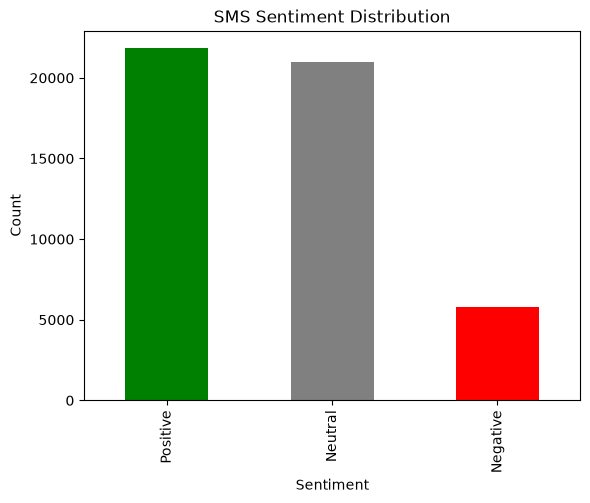

In [16]:
import matplotlib.pyplot as plt

df["sentiment"].value_counts().plot(
    kind="bar",
    color=["green", "grey", "red"]
)

plt.title("SMS Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")

plt.show()

In [17]:
df["sentiment"].value_counts()

sentiment
Positive    21827
Neutral     20966
Negative     5805
Name: count, dtype: int64

Sentiment Analysis Findings
Sentiment Distribution
The sentiment analysis revealed:

Positive Messages: 21,827
Neutral Messages: 20,966
Negative Messages: 5,805
Key Insights
Positive messages were the most common category.
Neutral messages accounted for a significant proportion of the dataset.
Negative messages represented the smallest category.
Interpretation
The results suggest that SMS conversations are generally neutral to positive in tone. Strongly negative messages occur less frequently than positive or neutral communication.

The prevalence of positive and neutral messages may reflect the everyday conversational nature of text messaging.

In [18]:
!pip install wordcloud

Defaulting to user installation because normal site-packages is not writeable


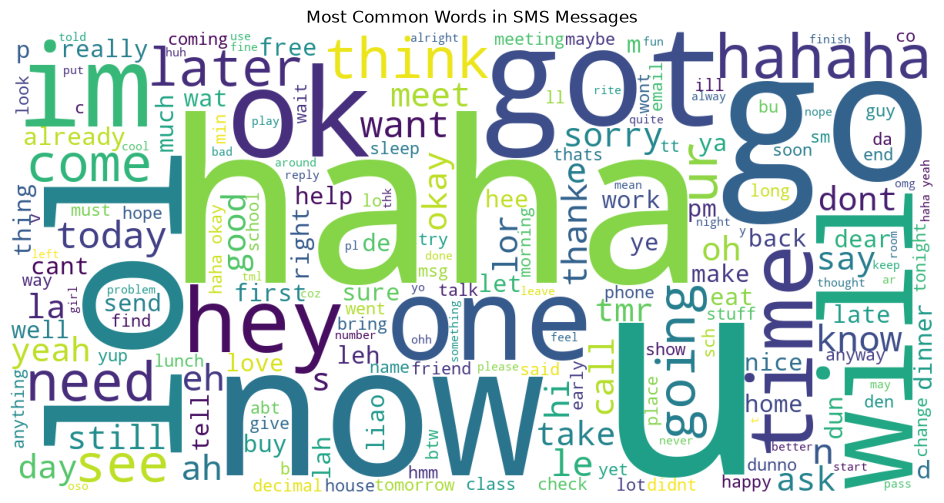

In [19]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = " ".join(df["clean_message"])

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white"
).generate(text)

plt.figure(figsize=(12,6))
plt.imshow(wordcloud)
plt.axis("off")
plt.title("Most Common Words in SMS Messages")

plt.show()

In [20]:
wordcloud.to_file("wordcloud.png")

Conclusion
This project applied Natural Language Processing (NLP) techniques to analyze a large SMS messaging dataset containing 48,598 messages.

Techniques used:

Text cleaning and preprocessing
Word frequency analysis
Sentiment analysis
Data visualization
Word cloud generation
Key Findings:

Most messages originated from Singapore.
Common words reflected informal conversational language.
Positive messages slightly outnumbered neutral messages.
Negative messages represented the smallest sentiment category.
NLP techniques provided useful insights into communication patterns within SMS conversations.
This project demonstrates practical applications of NLP for text analytics and communication data analysis using Python.